In [ ]:
%pip install pandas numpy matplotlib scikit-learn seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('height-weight.csv')

In [3]:
df.head()

,Height,Weight
0,150,45
1,152,53
2,154,43
3,156,55
4,158,47


# Explore Dataset (EDA)


In [5]:
print(df.head()) #shows first 5 rows
print(df.shape) #no of rows and cols
print(df.info()) #Shows column names, data types and non-null counts
print(df.describe()) #Calculates statistics such as mean, minimum and maximum
print(df.isnull().sum()) #Counts missing values in each column

   Height  Weight
0     150      45
1     152      53
2     154      43
3     156      55
4     158      47
(40, 2)
<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Height  40 non-null     int64
 1   Weight  40 non-null     int64
dtypes: int64(2)
memory usage: 772.0 bytes
None
           Height      Weight
count   40.000000   40.000000
mean   174.150000   74.225000
std     12.367347   17.671486
min    150.000000   43.000000
25%    164.750000   60.000000
50%    174.500000   73.500000
75%    184.250000   88.000000
max    195.000000  108.000000
Height    0
Weight    0
dtype: int64


# Plot Data

Text(0, 0.5, 'Height')

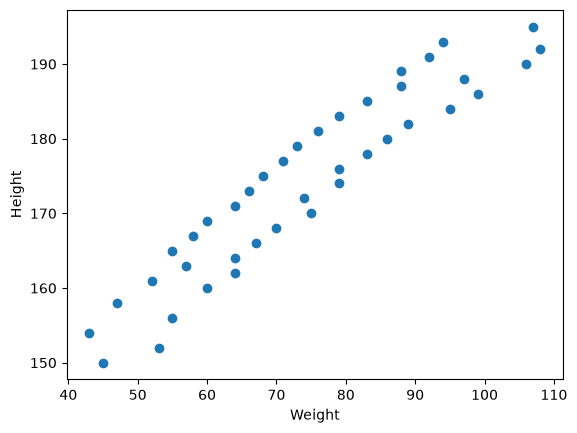

In [6]:
plt.scatter(df['Weight'], df['Height'])
plt.xlabel("Weight")
plt.ylabel("Height")

In [7]:
df.corr()

,Height,Weight
Height,1.000000,0.939722
Weight,0.939722,1.000000


## Independent and Dependent Features

*Independent feature* is written as dataframe or 2d Array.

In [ ]:
x = df[['Weight']]
y = df['Height']

# Train Test Split

## Separate input(X) and target(y)

In [ ]:
X = df[["Height"]] #We used double brackets for X because input should be a dataframe, while single bracket is considered as a Series
y = df["Weight"]

print(X.head())
print(y.head())

   Height
0     150
1     152
2     154
3     156
4     158
0    45
1    53
2    43
3    55
4    47
Name: Weight, dtype: int64


## Split into train and test

We don't want to evaluate our model only on data it has already seen. We therefore split the dataset into two parts.
- Training data: Used to learn the relationship between height and weight.
- Testing data: Held back to evaluate how well the model predicts unseen observations.
test_size=0.2 reserves 20% for testing. With 15 rows, this gives 12 training rows and 3 testing rows.
random_state=42 makes the random split reproducible. You can use another integer; 42 has no special mathematical significance.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 32
Testing rows: 8


# Train Linear Regression model

In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.29]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Height']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-150
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


The fit() method learns the slope and intercept from the training observations.

It chooses coefficients that minimize the sum of squared differences between actual training weights and predicted weights. These differences are called residuals.


### Inspect what model learned

In [12]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 1.2877271443083935
Intercept: -150.02899752943938


- model.coef_[0] gives the learned slope for Height.
- model.intercept_ gives the learned intercept.
The slope represents the model's predicted change in weight, in kilograms, for each additional centimetre of height. It describes the fitted relationship in this dataset; it does not establish that increasing someone's height causes their weight to change.

## Make predictions

In [13]:
y_pred = model.predict(X_test)

print("Actual weights:")
print(y_test.to_list())

print("Predicted weights:")
print(y_pred)

Actual weights:
[79, 64, 75, 76, 47, 58, 108, 89]
Predicted weights:
[74.03552558 70.17234415 68.884617   83.04961559 53.43189127 65.02143557
 97.21461418 84.33734273]


Here, predict() uses the learned equation to estimate the weights for heights in X_test.
y_test contains the real values, while y_pred contains the model's estimates. Comparing them helps us evaluate performance on data that was not used for training.

# Evaluate the model

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 6.650398385419486
MSE: 47.32169132598036
RMSE: 6.879076342502703
R² Score: 0.8482062828356685


- **Mean Absolute Error (MAE):** The average absolute prediction error. If MAE is 3, predictions miss the actual weight by 3 kg on average in absolute terms.

- **Mean Squared Error (MSE):** Squares the errors before averaging, so large errors receive greater weight. Its unit here is kg².

- **Root MSE (RMSE):** Returns the error to the original unit, kilograms. It penalizes large errors more strongly than MAE.

- **R squared** = Measures model performance relative to predicting the mean of the test targets. A score of 1 is a perfect fit; 0 means performance equivalent to that mean baseline on the evaluated data; a negative score means worse performance than the baseline.

# Visualize the line

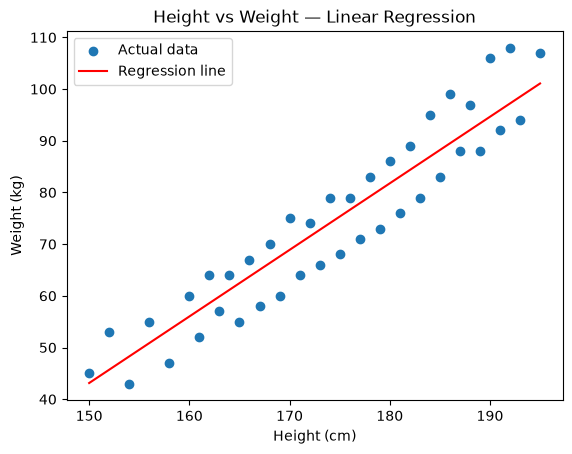

In [15]:
import matplotlib.pyplot as plt

plt.scatter(X["Height"], y, label="Actual data")

plt.plot(
    X["Height"],
    model.predict(X),
    color="red",
    label="Regression line"
)

plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Height vs Weight — Linear Regression")
plt.legend()
plt.show()

## predict weight for a new height

In [16]:
new_person = pd.DataFrame({"Height": [175]})

predicted_weight = model.predict(new_person)

print("Predicted weight:", predicted_weight[0], "kg")

Predicted weight: 75.32325272452948 kg
